Initial class distribution:
belly_pain: 16 samples
burping: 8 samples
discomfort: 27 samples
FullNormal: 21 samples
Full_asphyxia: 6 samples
Full_deaf: 52 samples
hungry: 382 samples
tired: 24 samples
belly_pain data is loading...
belly_pain data loaded with augmentation...
burping data is loading...
burping data loaded with augmentation...
discomfort data is loading...
discomfort data loaded with augmentation...
FullNormal data is loading...
FullNormal data loaded with augmentation...
Full_asphyxia data is loading...
Full_asphyxia data loaded with augmentation...
Full_deaf data is loading...
Full_deaf data loaded with augmentation...
hungry data is loading...
hungry data loaded with augmentation...
tired data is loading...
tired data loaded with augmentation...

Class distribution after augmentation:
belly_pain: 176 samples
burping: 88 samples
discomfort: 297 samples
FullNormal: 231 samples
Full_asphyxia: 66 samples
Full_deaf: 416 samples
hungry: 382 samples
tired: 264 samples
Trainin

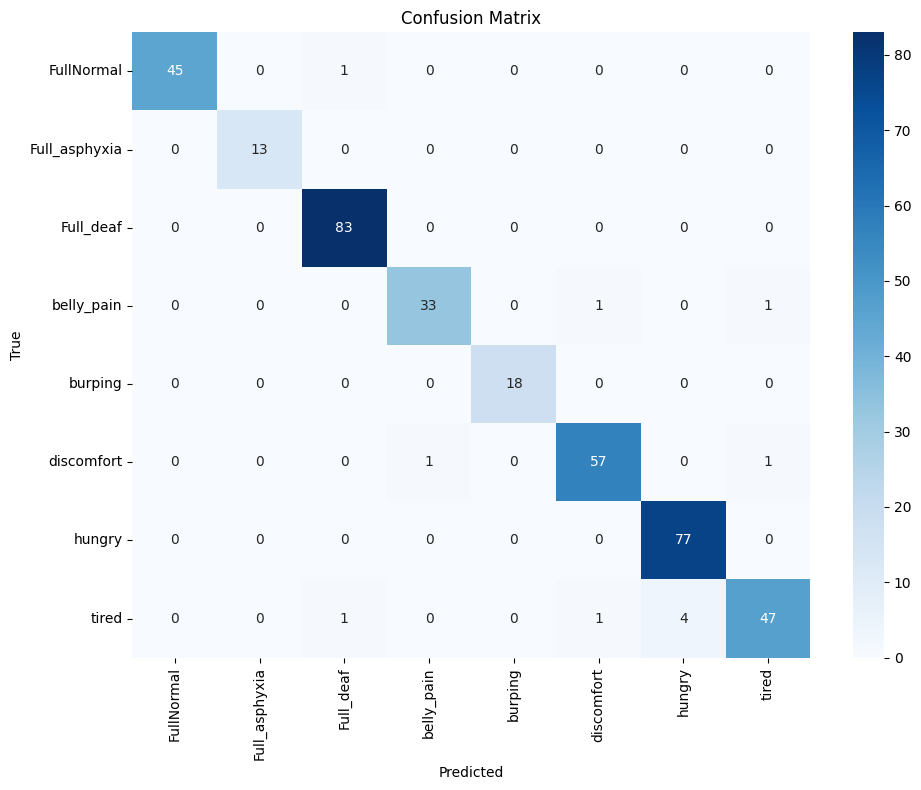

C:\Users\visha\AppData\Local\Temp\ipykernel_35044\57689630.py:301: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")


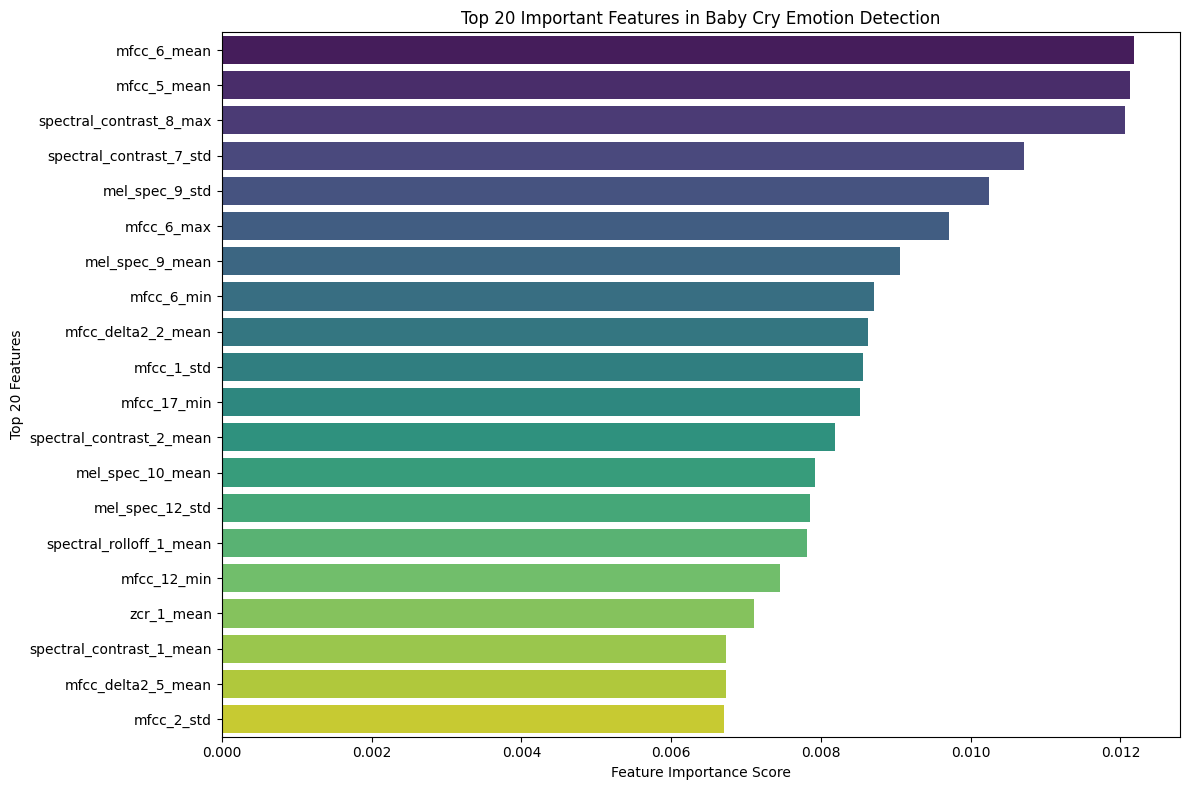


Top 20 Important Features:
mfcc_6_mean: 0.0122
mfcc_5_mean: 0.0121
spectral_contrast_8_max: 0.0121
spectral_contrast_7_std: 0.0107
mel_spec_9_std: 0.0102
mfcc_6_max: 0.0097
mel_spec_9_mean: 0.0091
mfcc_6_min: 0.0087
mfcc_delta2_2_mean: 0.0086
mfcc_1_std: 0.0086
mfcc_17_min: 0.0085
spectral_contrast_2_mean: 0.0082
mel_spec_10_mean: 0.0079
mel_spec_12_std: 0.0079
spectral_rolloff_1_mean: 0.0078
mfcc_12_min: 0.0075
zcr_1_mean: 0.0071
spectral_contrast_1_mean: 0.0067
mfcc_delta2_5_mean: 0.0067
mfcc_2_std: 0.0067
Model saved as 'baby_chill.pkl


In [2]:
import os
import numpy as np
import librosa
import scipy.signal as signal
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
import time
import random
from imblearn.over_sampling import SMOTE
from collections import Counter
from scipy.stats import skew, kurtosis




# **Pre-emphasis Function**
def pre_emphasis(signal, alpha=0.97):
    return np.append(signal[0], signal[1:] - alpha * signal[:-1])

# **Bandpass Filter Function (142.91 Hz - 6620.12 Hz)**
def bandpass_filter(y, sr=16000, lowcut=142.91, highcut=6620.12, order=5):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = signal.butter(order, [low, high], btype='band')
    return signal.filtfilt(b, a, y)


def extract_features(audio_data, sr=16000, n_mfcc=40, n_fft=1024, hop_length=160, win_length=400, window='hann',
                     n_chroma=12, n_mels=13, n_bands=7, fmin=100, bins_per_octave=12, tempogram_win=384, spectral_roll_percent=0.95):
    try:
        # Apply Pre-emphasis
        y = pre_emphasis(audio_data, alpha=0.97)

        # Apply Bandpass Filter
        y = bandpass_filter(y, sr=sr)

        # Zero Crossing Rate & RMS
        zcr = librosa.feature.zero_crossing_rate(y, frame_length=win_length, hop_length=hop_length)
        rms = librosa.feature.rms(y=y, frame_length=win_length, hop_length=hop_length)

        # STFT and Spectral Features
        stft = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length, win_length=win_length))
        S, phase = librosa.magphase(stft)

        # MFCC and Deltas
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop_length,
                                   win_length=win_length, window=window)
        mfcc_delta = librosa.feature.delta(mfcc)
        mfcc_delta2 = librosa.feature.delta(mfcc, order=2)

        # Advanced Spectral Features
        spectral_centroid = librosa.feature.spectral_centroid(S=S, sr=sr)
        spectral_bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=sr)
        spectral_rolloff = librosa.feature.spectral_rolloff(S=S, sr=sr, roll_percent=spectral_roll_percent)
        spectral_contrast = librosa.feature.spectral_contrast(S=S, sr=sr, n_bands=n_bands, fmin=fmin)
        chroma = librosa.feature.chroma_stft(S=S, sr=sr, n_chroma=n_chroma)
        mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length,
                                                 win_length=win_length, n_mels=n_mels)
        tonnetz = librosa.feature.tonnetz(y=y, sr=sr)

        # Temporal Features

        # Feature aggregation with statistics
        feature_functions = [
            (mfcc, 'mfcc', ['mean', 'std', 'skew', 'max', 'min']),
            (mfcc_delta, 'mfcc_delta', ['mean', 'std']),
            (mfcc_delta2, 'mfcc_delta2', ['mean', 'std']),
            (zcr, 'zcr', ['mean', 'std', 'max']),
            (rms, 'rms', ['mean', 'std', 'max', 'min']),
            (spectral_centroid, 'spectral_centroid', ['mean', 'std', 'max']),
            (spectral_bandwidth, 'spectral_bandwidth', ['mean', 'std', 'max']),
            (spectral_rolloff, 'spectral_rolloff', ['mean', 'std']),
            (spectral_contrast, 'spectral_contrast', ['mean', 'std', 'max']),
            (chroma, 'chroma', ['mean', 'std']),
            (mel_spec, 'mel_spec', ['mean', 'std']),
            (tonnetz, 'tonnetz', ['mean', 'std']),
        ]

        features = []
        feature_names = []

        for feat, feat_name, stats in feature_functions:
            for i in range(feat.shape[0]):
                if 'mean' in stats: 
                    features.append(np.mean(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_mean")
                if 'std' in stats: 
                    features.append(np.std(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_std")
                if 'skew' in stats: 
                    features.append(skew(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_skew")
                if 'kurt' in stats: 
                    features.append(kurtosis(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_kurt")
                if 'max' in stats: 
                    features.append(np.max(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_max")
                if 'min' in stats: 
                    features.append(np.min(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_min")

        # Return both features and their names
        return np.array(features), feature_names
    except Exception as e:
        print(f"Error processing audio data: {e}")
        return None, None


# **Data Augmentation Functions**
def time_stretching(y, rate):
    """Time stretching without changing pitch"""
    return librosa.effects.time_stretch(y, rate=rate)

def pitch_shifting(y, sr, n_steps):
    """Pitch shifting without changing tempo"""
    return librosa.effects.pitch_shift(y, sr=sr, n_steps=n_steps)

def add_noise(y, noise_factor=0.005):
    """Add random noise to the audio"""
    noise = np.random.randn(len(y))
    return y + noise_factor * noise

def random_gain(y, min_factor=0.7, max_factor=1.3):
    """Apply random gain to the audio"""
    gain_factor = np.random.uniform(min_factor, max_factor)
    return y * gain_factor

def time_shifting(y, shift_factor=0.2):
    """Shift audio in time (circular shift)"""
    shift_amount = int(len(y) * shift_factor)
    return np.roll(y, shift_amount)

def augment_audio(y, sr):
    """Apply random augmentation technique to audio"""
    augmentation_techniques = [
        lambda: time_stretching(y, rate=np.random.uniform(0.85, 1.15)),
        lambda: pitch_shifting(y, sr, n_steps=np.random.uniform(-2, 2)),
        lambda: add_noise(y, noise_factor=np.random.uniform(0.001, 0.01)),
        lambda: random_gain(y),
        lambda: time_shifting(y, shift_factor=np.random.uniform(0.1, 0.3))
    ]
    
    # Randomly select two augmentation techniques
    chosen_techniques = np.random.choice(len(augmentation_techniques), size=2, replace=False)
    
    augmented_y = y.copy()
    for idx in chosen_techniques:
        augmented_y = augmentation_techniques[idx]()
    
    return augmented_y

# Global variable to store feature names
all_feature_names = []

# **Load Dataset with Augmentation**
path = r"D:\SEM6\Speech Processing\datasets\donateacry_corpus"
features = []
labels = []

# Get initial class counts to determine augmentation needed
initial_counts = {}
for label in os.listdir(path):
    file_count = len(os.listdir(os.path.join(path, label)))
    initial_counts[label] = file_count
    
print("Initial class distribution:")
for label, count in initial_counts.items():
    print(f"{label}: {count} samples")

# Find majority class
majority_class_count = max(initial_counts.values())

# **Extract Features with Augmentation**
for label in os.listdir(path):
    print(f"{label} data is loading...")
    label_files = os.listdir(os.path.join(path, label))
    augmentation_factor = int(np.ceil(majority_class_count / len(label_files))) - 1
    
    # Process original files
    for file_name in label_files:
        file_path = os.path.join(path, label, file_name)
        
        # Load audio file
        y, sr = librosa.load(file_path, sr=16000)
        
        # Extract features from original audio
        feature, feature_names = extract_features(y, sr=sr)
        if feature is not None:
            features.append(feature)
            labels.append(label)
            
            # Store feature names only once
            if not all_feature_names and feature_names is not None:
                all_feature_names = feature_names
        
        # Apply augmentation if needed (for minority classes)
        if augmentation_factor > 0:
            for _ in range(min(augmentation_factor, 10)):  # Cap at 10 augmentations per file
                augmented_y = augment_audio(y, sr)
                augmented_feature, _ = extract_features(augmented_y, sr=sr)
                if augmented_feature is not None:
                    features.append(augmented_feature)
                    labels.append(label)
    
    print(f"{label} data loaded with augmentation...")

# Check if feature dimensions are consistent
feature_lengths = [len(f) for f in features]
if len(set(feature_lengths)) > 1:
    print(f"Warning: Inconsistent feature lengths detected: {set(feature_lengths)}")
    # Find the most common length
    from collections import Counter
    most_common_length = Counter(feature_lengths).most_common(1)[0][0]
    
    # Filter to keep only features with the most common length
    valid_indices = [i for i, length in enumerate(feature_lengths) if length == most_common_length]
    features = [features[i] for i in valid_indices]
    labels = [labels[i] for i in valid_indices]
    print(f"Filtered to {len(features)} samples with consistent feature length of {most_common_length}")

# **Convert to NumPy Arrays**
features = np.array(features)
labels = np.array(labels)

# Show class distribution after augmentation
print("\nClass distribution after augmentation:")
for label, count in Counter(labels).items():
    print(f"{label}: {count} samples")

# **Encode Labels**
le = LabelEncoder()
labels = le.fit_transform(labels)



# **Split Data**
X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.20, stratify=labels)

# Apply SMOTE for balancing the training data
smote = SMOTE()
X_train, y_train = smote.fit_resample(X_train, y_train)

print(f"Training data shape after SMOTE: {X_train.shape}")
print(f"Number of features: {X_train.shape[1]}")

# **Train Weighted Random Forest Classifier**
start_time = time.time()
rf = RandomForestClassifier(
    n_estimators=500, 
    max_depth=20, 
    class_weight="balanced", 
    n_jobs=-1  # Use all available cores
)
rf.fit(X_train, y_train)
runtime = time.time() - start_time

# **Predict**
y_pred = rf.predict(X_test)

# **Evaluate Performance**
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")

# **Print Results**
print(f"Accuracy: {accuracy:.4f}, F1 Score: {f1:.4f}, Recall: {recall:.4f}, Runtime: {runtime:.2f} sec")

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)
class_names = le.classes_

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

# Get feature importances
if len(all_feature_names) == X_train.shape[1]:
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(all_feature_names, feature_importances))
    
    # **Sort and Get Top 20 Features**
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    # Print top 20 features with importance sco
    
    # **Plot Feature Importance**
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()
    
    # Print top 20 features with importance scores
    print("\nTop 20 Important Features:")
    for feature, importance in sorted_features:
        print(f"{feature}: {importance:.4f}")
else:
    print(f"Error: Feature names count ({len(all_feature_names)}) doesn't match feature count ({X_train.shape[1]})")
    # Use generic feature names as fallback
    generic_feature_names = [f"feature_{i}" for i in range(X_train.shape[1])]
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(generic_feature_names, feature_importances))
    
    # Sort and get top 20
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()

# Save the model and feature names for future use
import pickle
model_info = {
    'model': rf,
    'feature_names': all_feature_names,
    'class_names': class_names,
    'performance': {
        'accuracy': accuracy,
        'f1': f1,
        'recall': recall
    }
}

with open('baby_chill.pkl', 'wb') as f:
    pickle.dump(model_info, f)

print("Model saved as 'baby_chill.pkl")

Initial class distribution:
1s_asphyxia: 340 samples
1s_deaf: 879 samples
1s_hunger: 350 samples
1s_normal: 507 samples
1s_pain: 192 samples
1s_asphyxia data is loading...
1s_asphyxia data loaded with augmentation...
1s_deaf data is loading...
1s_deaf data loaded with augmentation...
1s_hunger data is loading...
1s_hunger data loaded with augmentation...
1s_normal data is loading...
1s_normal data loaded with augmentation...
1s_pain data is loading...
1s_pain data loaded with augmentation...

Class distribution after augmentation:
1s_asphyxia: 1020 samples
1s_deaf: 879 samples
1s_hunger: 1050 samples
1s_normal: 1014 samples
1s_pain: 960 samples
Training data shape after SMOTE: (4200, 461)
Number of features: 461
Accuracy: 0.9604, F1 Score: 0.9603, Recall: 0.9604, Runtime: 3.89 sec


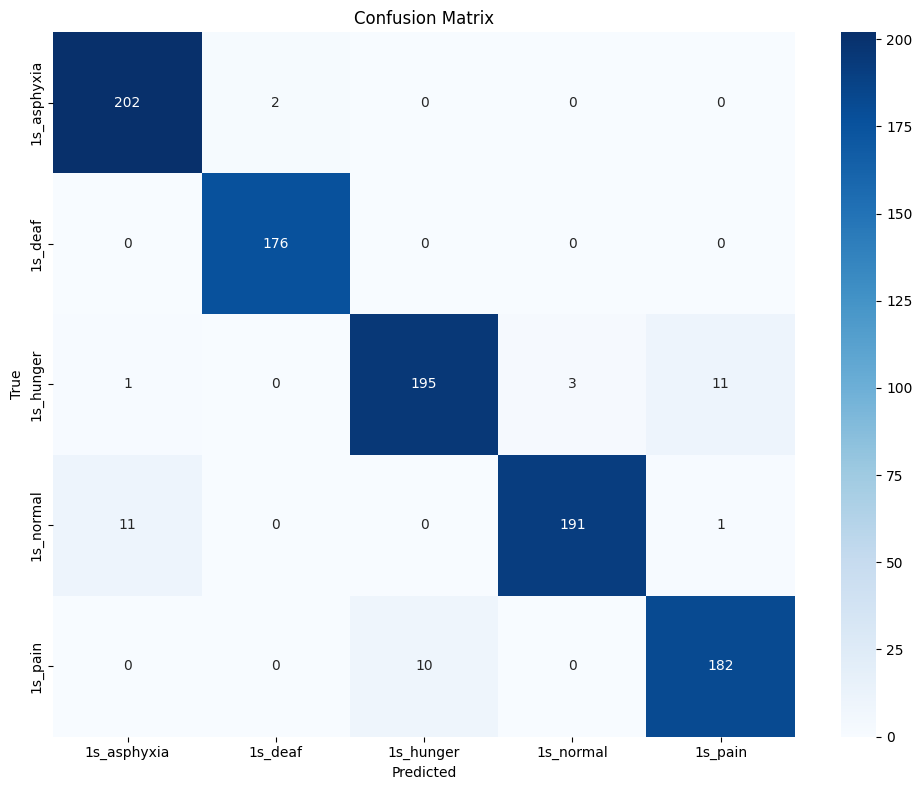

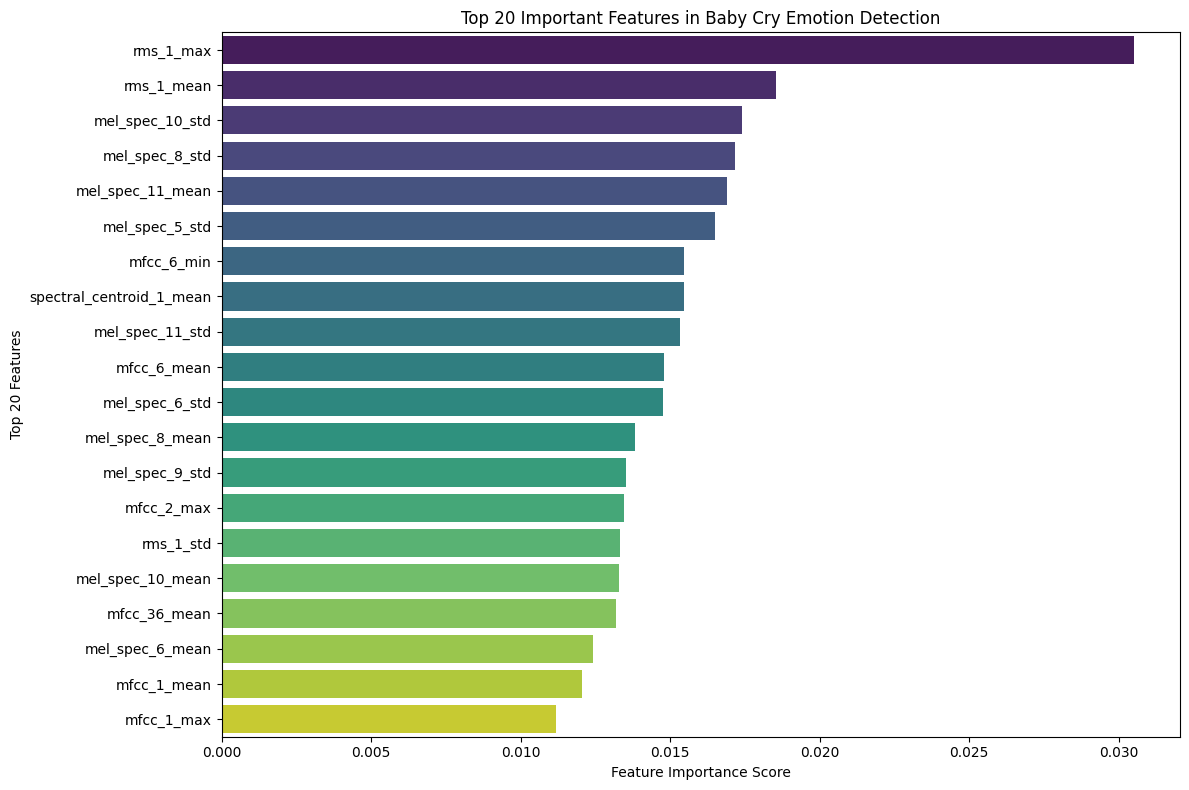


Top 20 Important Features:
rms_1_max: 0.0305
rms_1_mean: 0.0185
mel_spec_10_std: 0.0174
mel_spec_8_std: 0.0172
mel_spec_11_mean: 0.0169
mel_spec_5_std: 0.0165
mfcc_6_min: 0.0155
spectral_centroid_1_mean: 0.0154
mel_spec_11_std: 0.0153
mfcc_6_mean: 0.0148
mel_spec_6_std: 0.0148
mel_spec_8_mean: 0.0138
mel_spec_9_std: 0.0135
mfcc_2_max: 0.0135
rms_1_std: 0.0133
mel_spec_10_mean: 0.0133
mfcc_36_mean: 0.0132
mel_spec_6_mean: 0.0124
mfcc_1_mean: 0.0120
mfcc_1_max: 0.0112
Model saved as 'baby_chillsec.pkl


In [ ]:
import os
import numpy as np
import librosa
import scipy.signal as signal
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
import time
import random
from imblearn.over_sampling import SMOTE
from collections import Counter
from scipy.stats import skew, kurtosis




# **Pre-emphasis Function**
def pre_emphasis(signal, alpha=0.97):
    return np.append(signal[0], signal[1:] - alpha * signal[:-1])

# **Bandpass Filter Function (142.91 Hz - 6620.12 Hz)**
def bandpass_filter(y, sr=16000, lowcut=142.91, highcut=6620.12, order=5):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = signal.butter(order, [low, high], btype='band')
    return signal.filtfilt(b, a, y)


def extract_features(audio_data, sr=16000, n_mfcc=40, n_fft=256, hop_length=50, win_length=100, window='hann',
                     n_chroma=12, n_mels=13, n_bands=7, fmin=100, bins_per_octave=12, tempogram_win=384, spectral_roll_percent=0.95):
    try:
        # Apply Pre-emphasis
        y = pre_emphasis(audio_data, alpha=0.97)

        # Apply Bandpass Filter
        y = bandpass_filter(y, sr=sr)

        # Zero Crossing Rate & RMS
        zcr = librosa.feature.zero_crossing_rate(y, frame_length=win_length, hop_length=hop_length)
        rms = librosa.feature.rms(y=y, frame_length=win_length, hop_length=hop_length)

        # STFT and Spectral Features
        stft = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length, win_length=win_length))
        S, phase = librosa.magphase(stft)

        # MFCC and Deltas
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop_length,
                                   win_length=win_length, window=window)
        mfcc_delta = librosa.feature.delta(mfcc)
        mfcc_delta2 = librosa.feature.delta(mfcc, order=2)

        # Advanced Spectral Features
        spectral_centroid = librosa.feature.spectral_centroid(S=S, sr=sr)
        spectral_bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=sr)
        spectral_rolloff = librosa.feature.spectral_rolloff(S=S, sr=sr, roll_percent=spectral_roll_percent)
        spectral_contrast = librosa.feature.spectral_contrast(S=S, sr=sr, n_bands=n_bands, fmin=fmin)
        chroma = librosa.feature.chroma_stft(S=S, sr=sr, n_chroma=n_chroma)
        mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length,
                                                 win_length=win_length, n_mels=n_mels)
        tonnetz = librosa.feature.tonnetz(y=y, sr=sr)

        # Temporal Features

        # Feature aggregation with statistics
        feature_functions = [
            (mfcc, 'mfcc', ['mean', 'std', 'skew', 'max', 'min']),
            (mfcc_delta, 'mfcc_delta', ['mean', 'std']),
            (mfcc_delta2, 'mfcc_delta2', ['mean', 'std']),
            (zcr, 'zcr', ['mean', 'std', 'max']),
            (rms, 'rms', ['mean', 'std', 'max', 'min']),
            (spectral_centroid, 'spectral_centroid', ['mean', 'std', 'max']),
            (spectral_bandwidth, 'spectral_bandwidth', ['mean', 'std', 'max']),
            (spectral_rolloff, 'spectral_rolloff', ['mean', 'std']),
            (spectral_contrast, 'spectral_contrast', ['mean', 'std', 'max']),
            (chroma, 'chroma', ['mean', 'std']),
            (mel_spec, 'mel_spec', ['mean', 'std']),
            (tonnetz, 'tonnetz', ['mean', 'std']),
        ]

        features = []
        feature_names = []

        for feat, feat_name, stats in feature_functions:
            for i in range(feat.shape[0]):
                if 'mean' in stats: 
                    features.append(np.mean(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_mean")
                if 'std' in stats: 
                    features.append(np.std(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_std")
                if 'skew' in stats: 
                    features.append(skew(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_skew")
                if 'kurt' in stats: 
                    features.append(kurtosis(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_kurt")
                if 'max' in stats: 
                    features.append(np.max(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_max")
                if 'min' in stats: 
                    features.append(np.min(feat[i]))
                    feature_names.append(f"{feat_name}_{i+1}_min")

        # Return both features and their names
        return np.array(features), feature_names
    except Exception as e:
        print(f"Error processing audio data: {e}")
        return None, None


# **Data Augmentation Functions**
def time_stretching(y, rate):
    """Time stretching without changing pitch"""
    return librosa.effects.time_stretch(y, rate=rate)

def pitch_shifting(y, sr, n_steps):
    """Pitch shifting without changing tempo"""
    return librosa.effects.pitch_shift(y, sr=sr, n_steps=n_steps)

def add_noise(y, noise_factor=0.005):
    """Add random noise to the audio"""
    noise = np.random.randn(len(y))
    return y + noise_factor * noise

def random_gain(y, min_factor=0.7, max_factor=1.3):
    """Apply random gain to the audio"""
    gain_factor = np.random.uniform(min_factor, max_factor)
    return y * gain_factor

def time_shifting(y, shift_factor=0.2):
    """Shift audio in time (circular shift)"""
    shift_amount = int(len(y) * shift_factor)
    return np.roll(y, shift_amount)

def augment_audio(y, sr):
    """Apply random augmentation technique to audio"""
    augmentation_techniques = [
        lambda: time_stretching(y, rate=np.random.uniform(0.85, 1.15)),
        lambda: pitch_shifting(y, sr, n_steps=np.random.uniform(-2, 2)),
        lambda: add_noise(y, noise_factor=np.random.uniform(0.001, 0.01)),
        lambda: random_gain(y),
        lambda: time_shifting(y, shift_factor=np.random.uniform(0.1, 0.3))
    ]
    
    # Randomly select two augmentation techniques
    chosen_techniques = np.random.choice(len(augmentation_techniques), size=2, replace=False)
    
    augmented_y = y.copy()
    for idx in chosen_techniques:
        augmented_y = augmentation_techniques[idx]()
    
    return augmented_y

# Global variable to store feature names
all_feature_names = []

# **Load Dataset with Augmentation**
path = r"C:\Users\visha\OneDrive\Desktop\New folder"
features = []
labels = []

# Get initial class counts to determine augmentation needed
initial_counts = {}
for label in os.listdir(path):
    file_count = len(os.listdir(os.path.join(path, label)))
    initial_counts[label] = file_count
    
print("Initial class distribution:")
for label, count in initial_counts.items():
    print(f"{label}: {count} samples")

# Find majority class
majority_class_count = max(initial_counts.values())

# **Extract Features with Augmentation**
for label in os.listdir(path):
    print(f"{label} data is loading...")
    label_files = os.listdir(os.path.join(path, label))
    augmentation_factor = int(np.ceil(majority_class_count / len(label_files))) - 1
    
    # Process original files
    for file_name in label_files:
        file_path = os.path.join(path, label, file_name)
        
        # Load audio file
        y, sr = librosa.load(file_path, sr=16000)
        
        # Extract features from original audio
        feature, feature_names = extract_features(y, sr=sr)
        if feature is not None:
            features.append(feature)
            labels.append(label)
            
            # Store feature names only once
            if not all_feature_names and feature_names is not None:
                all_feature_names = feature_names
        
        # Apply augmentation if needed (for minority classes)
        if augmentation_factor > 0:
            for _ in range(min(augmentation_factor, 10)):  # Cap at 10 augmentations per file
                augmented_y = augment_audio(y, sr)
                augmented_feature, _ = extract_features(augmented_y, sr=sr)
                if augmented_feature is not None:
                    features.append(augmented_feature)
                    labels.append(label)
    
    print(f"{label} data loaded with augmentation...")

# Check if feature dimensions are consistent
feature_lengths = [len(f) for f in features]
if len(set(feature_lengths)) > 1:
    print(f"Warning: Inconsistent feature lengths detected: {set(feature_lengths)}")
    # Find the most common length
    from collections import Counter
    most_common_length = Counter(feature_lengths).most_common(1)[0][0]
    
    # Filter to keep only features with the most common length
    valid_indices = [i for i, length in enumerate(feature_lengths) if length == most_common_length]
    features = [features[i] for i in valid_indices]
    labels = [labels[i] for i in valid_indices]
    print(f"Filtered to {len(features)} samples with consistent feature length of {most_common_length}")

# **Convert to NumPy Arrays**
features = np.array(features)
labels = np.array(labels)

# Show class distribution after augmentation
print("\nClass distribution after augmentation:")
for label, count in Counter(labels).items():
    print(f"{label}: {count} samples")

# **Encode Labels**
le = LabelEncoder()
labels = le.fit_transform(labels)



# **Split Data**
X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.20, stratify=labels)

# Apply SMOTE for balancing the training data
smote = SMOTE()
X_train, y_train = smote.fit_resample(X_train, y_train)

print(f"Training data shape after SMOTE: {X_train.shape}")
print(f"Number of features: {X_train.shape[1]}")

# **Train Weighted Random Forest Classifier**
start_time = time.time()
rf = RandomForestClassifier(
    n_estimators=500, 
    max_depth=20, 
    class_weight="balanced", 
    n_jobs=-1  # Use all available cores
)
rf.fit(X_train, y_train)
runtime = time.time() - start_time

# **Predict**
y_pred = rf.predict(X_test)

# **Evaluate Performance**
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")

# **Print Results**
print(f"Accuracy: {accuracy:.4f}, F1 Score: {f1:.4f}, Recall: {recall:.4f}, Runtime: {runtime:.2f} sec")

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)
class_names = le.classes_

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

# Get feature importances
if len(all_feature_names) == X_train.shape[1]:
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(all_feature_names, feature_importances))
    
    # **Sort and Get Top 20 Features**
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    # Print top 20 features with importance sco
    
    # **Plot Feature Importance**
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()
    
    # Print top 20 features with importance scores
    print("\nTop 20 Important Features:")
    for feature, importance in sorted_features:
        print(f"{feature}: {importance:.4f}")
else:
    print(f"Error: Feature names count ({len(all_feature_names)}) doesn't match feature count ({X_train.shape[1]})")
    # Use generic feature names as fallback
    generic_feature_names = [f"feature_{i}" for i in range(X_train.shape[1])]
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(generic_feature_names, feature_importances))
    
    # Sort and get top 20
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()

# Save the model and feature names for future use
import pickle
model_info = {
    'model': rf,
    'feature_names': all_feature_names,
    'class_names': class_names,
    'performance': {
        'accuracy': accuracy,
        'f1': f1,
        'recall': recall
    }
}

with open('baby_chillsec.pkl', 'wb') as f:
    pickle.dump(model_info, f)

print("Model saved as 'baby_chillsec.pkl")

Accuracy: 0.9766, F1 Score: 0.9763, Recall: 0.9766, Runtime: 1.06 sec


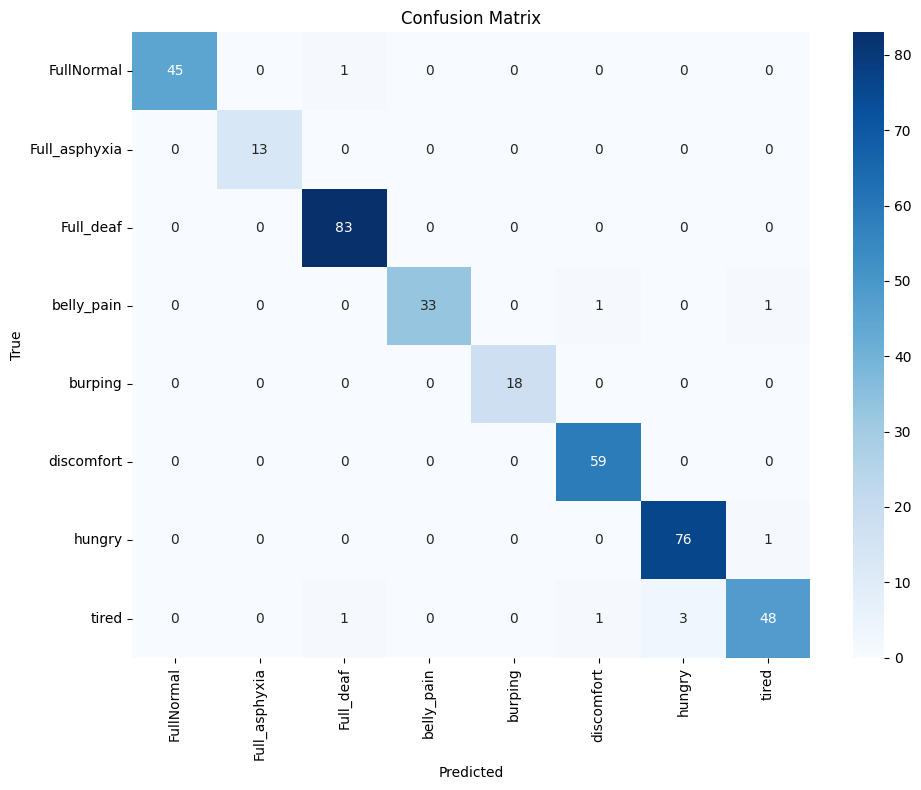

C:\Users\visha\AppData\Local\Temp\ipykernel_35044\3747815459.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")


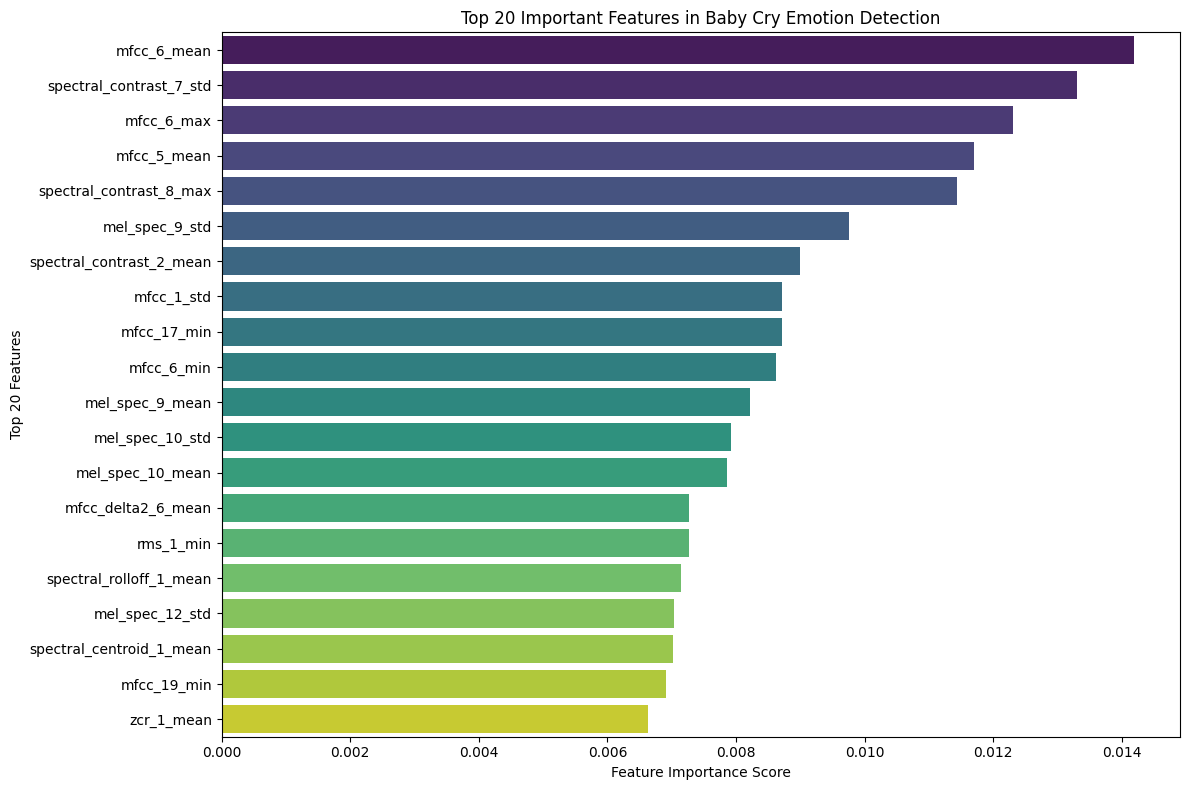


Top 20 Important Features:
mfcc_6_mean: 0.0142
spectral_contrast_7_std: 0.0133
mfcc_6_max: 0.0123
mfcc_5_mean: 0.0117
spectral_contrast_8_max: 0.0114
mel_spec_9_std: 0.0098
spectral_contrast_2_mean: 0.0090
mfcc_1_std: 0.0087
mfcc_17_min: 0.0087
mfcc_6_min: 0.0086
mel_spec_9_mean: 0.0082
mel_spec_10_std: 0.0079
mel_spec_10_mean: 0.0079
mfcc_delta2_6_mean: 0.0073
rms_1_min: 0.0073
spectral_rolloff_1_mean: 0.0071
mel_spec_12_std: 0.0070
spectral_centroid_1_mean: 0.0070
mfcc_19_min: 0.0069
zcr_1_mean: 0.0066
Model saved as 'baby_chill1.pkl


In [9]:
start_time = time.time()
rf = RandomForestClassifier(
    n_estimators=300, 
    max_depth=20, 
    class_weight="balanced", 
    n_jobs=-1  # Use all available cores
)
rf.fit(X_train, y_train)
runtime = time.time() - start_time

# **Predict**
y_pred = rf.predict(X_test)

# **Evaluate Performance**
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")

# **Print Results**
print(f"Accuracy: {accuracy:.4f}, F1 Score: {f1:.4f}, Recall: {recall:.4f}, Runtime: {runtime:.2f} sec")

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)
class_names = le.classes_

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

# Get feature importances
if len(all_feature_names) == X_train.shape[1]:
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(all_feature_names, feature_importances))
    
    # **Sort and Get Top 20 Features**
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    # Print top 20 features with importance sco
    
    # **Plot Feature Importance**
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()
    
    # Print top 20 features with importance scores
    print("\nTop 20 Important Features:")
    for feature, importance in sorted_features:
        print(f"{feature}: {importance:.4f}")
else:
    print(f"Error: Feature names count ({len(all_feature_names)}) doesn't match feature count ({X_train.shape[1]})")
    # Use generic feature names as fallback
    generic_feature_names = [f"feature_{i}" for i in range(X_train.shape[1])]
    feature_importances = rf.feature_importances_
    feature_importance_dict = dict(zip(generic_feature_names, feature_importances))
    
    # Sort and get top 20
    sorted_features = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)[:20]
    top_features, top_importance = zip(*sorted_features)
    
    plt.figure(figsize=(12, 8))
    sns.barplot(x=list(top_importance), y=list(top_features), palette="viridis")
    plt.xlabel("Feature Importance Score")
    plt.ylabel("Top 20 Features")
    plt.title("Top 20 Important Features in Baby Cry Emotion Detection")
    plt.tight_layout()
    plt.savefig('feature_importance.png')
    plt.show()

# Save the model and feature names for future use
import pickle
model_info = {
    'model': rf,
    'feature_names': all_feature_names,
    'class_names': class_names,
    'performance': {
        'accuracy': accuracy,
        'f1': f1,
        'recall': recall
    }
}

with open('baby_chill1.pkl', 'wb') as f:
    pickle.dump(model_info, f)

print("Model saved as 'baby_chill1.pkl")